In [1]:
import numpy as np
import matplotlib.pyplot as plt
from SingleAgent import *

## Theoretical Qlearning values

In [2]:
delta_value = 0.17
epsilon_value = 0.1
lambda_value = 0
P, R, T, S = 0.2, 0.8, 1, 0

The Payoff Matrix:

| **Player A / Player B** | **Cooperate (C)** | **Defect (D)** |
|-------------------------|-------------------|----------------|
| **Cooperate (C)**       | R = 0.8           | S = 0          |
| **Defect (D)**          | T = 1.0           | P = 0.2        |

## Single Run

In [3]:
strategy = epsilon_GrimTrigger()
solver = PrisonersDilemmaSolver(
    strategy=strategy,
    e_initial=epsilon_value,
    lambda_val=lambda_value,
    alpha=0.1,
    delta=delta_value,
    K=100,
    M=4,
    e_decay=1,
    random_uniform=False,
    verbose=False
)

In [4]:
#critical delta *S
c2 = ((2*P) - (epsilon_value *P) - (epsilon_value *R) - (2 *S) + (epsilon_value *S) + (epsilon_value *T))/((-1 + epsilon_value) *((-2 *P) + (2 *epsilon_value *P) + (2 *S) - (epsilon_value *S) - (epsilon_value *T)))
c1 = (-epsilon_value *P + 2 *R - epsilon_value *R + epsilon_value *S - 2 *T + epsilon_value *T)/((-1 + epsilon_value)* (-2 *P + 2 *epsilon_value *P - epsilon_value *S + 2 *T - epsilon_value *T))

In [5]:
print(f'c1 is {round(c1,3)}', f'and c2 is {round(c2, 3)}')

c1 is 0.289 and c2 is 0.966


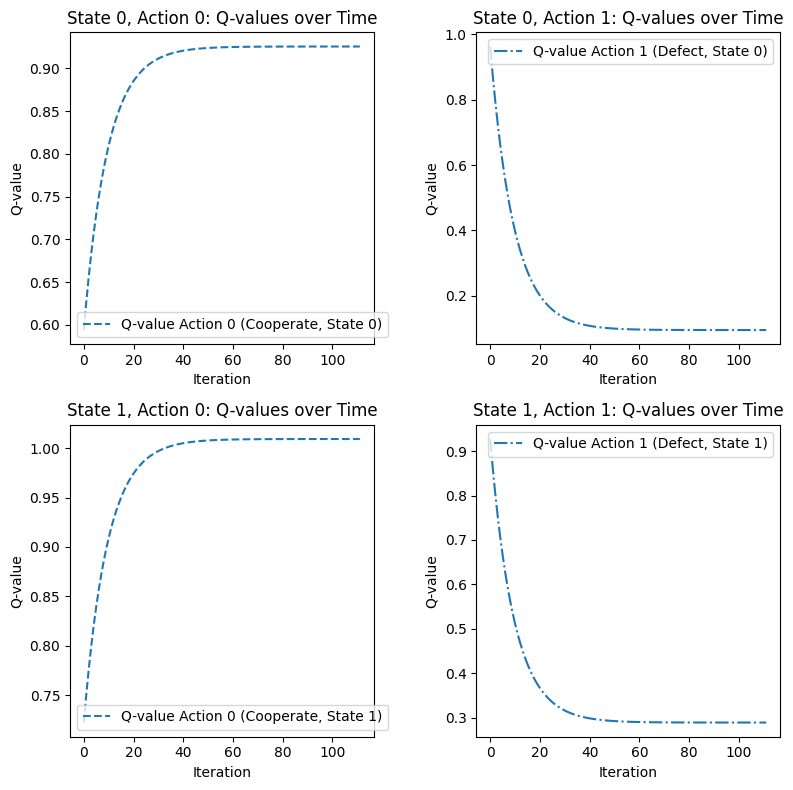

Cooperations: 25, Defections: 418


In [6]:
# Run the solver
cooperations, defections, q1_history, mean_q_values, grim_trigger_count_dict, initial_q_value = solver.run()
# Check results
print(f"Cooperations: {cooperations}, Defections: {defections}")


### Calculate Theoretical Q-Values

In [7]:
calculator = Theoretical_QValueCalculator(epsilon=epsilon_value, P=P, R=R, T=T, S=S)
Q00, Q01, Q10, Q11 = calculator.calculate_q_values(delta_value, c1, c2)

### Value Iteration Check

TypeError: plot_values() takes 11 positional arguments but 12 were given

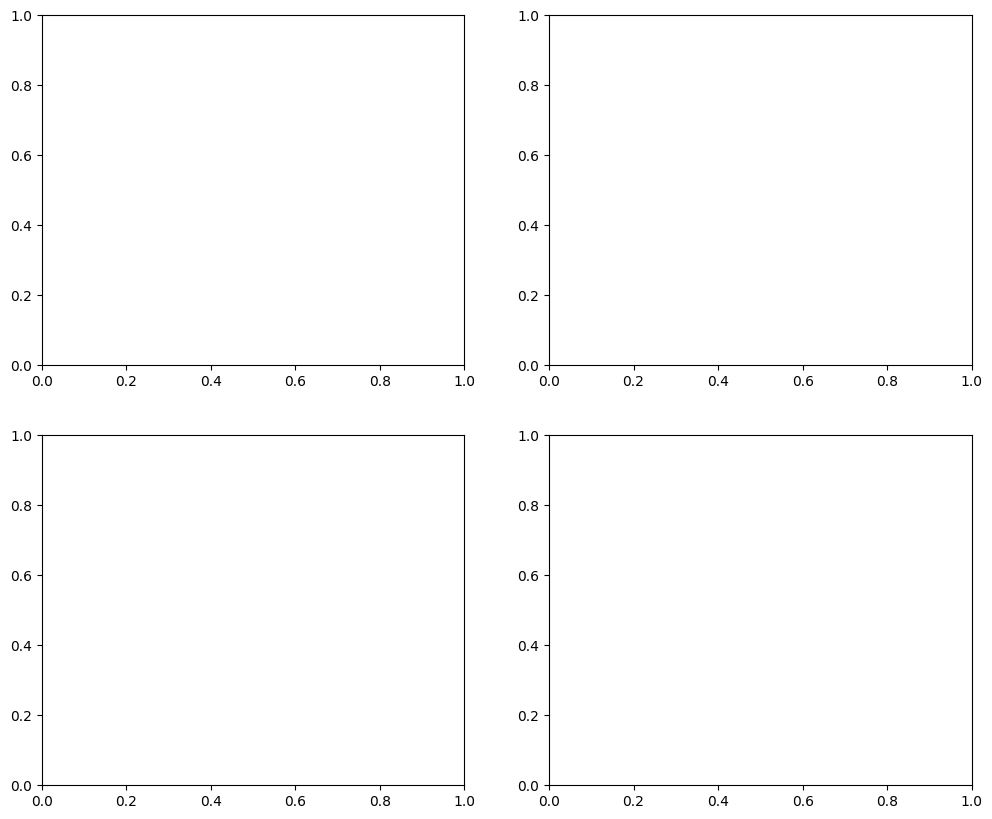

In [8]:
solver.plot_value_iteration(Q00, Q01, Q10, Q11, False)

In [ ]:
solver.plot_value_iteration()

In [ ]:
break

SyntaxError: 'break' outside loop (668683560.py, line 1)

## Multiple Random Seed

In [ ]:
seeds = random.sample(range(1, 10000), 10)

all_cooperations = []
all_defections = []

for seed in seeds:
    random.seed(seed)
    strategy = GrimTrigger_QValues()  # Or use TitForTat()
    solver = PrisonersDilemmaSolver(strategy, e_initial=epsilon_value, 
                                    lambda_val=0.1, 
                                    alpha=0.05, 
                                    delta=0.9, 
                                    K=100, 
                                    M=10, 
                                    e_decay=0.95, 
                                    verbose=False, plotting = False)
    
    cooperations, defections, q = solver.run()
    all_cooperations.append(cooperations)
    all_defections.append(defections)

all_cooperations = np.array(all_cooperations)
all_defections = np.array(all_defections)

mean_cooperations = np.mean(all_cooperations)
mean_defections = np.mean(all_defections)

print(f"Mean cooperations: {mean_cooperations}")
print(f"Mean defections: {mean_defections}")


NameError: name 'random' is not defined

## Critical Value of delta

In [ ]:
## Should this be changed, putting how many times it learns to play gt instead or number of cooperations?
break

In [ ]:
def analyze_critical_delta(strategy, e_initial, lambda_val, alpha, delta_range, K, M, e_decay, random_uniform=True):
    """
    Analyzes the critical value of delta for which the agent begins cooperating against the Grim Trigger strategy.
    
    Parameters:
        strategy: The opponent strategy (e.g., GrimTrigger).
        e_initial: Initial exploration rate for Q-learning.
        lambda_val: Eligibility decay parameter.
        alpha: Learning rate for Q-learning.
        delta_range: Tuple specifying the range of delta (min, max, step).
        K: Number of iterations per episode.
        M: Number of episodes to train.
        e_decay: Decay rate for exploration rate.
        random_uniform: Whether to initialize Q-values randomly.
    
    Returns:
        A plot of cooperation ratio vs. delta.
    """
    deltas = np.arange(delta_range[0], delta_range[1], delta_range[2])
    cooperation_ratios = []

    for delta in deltas:
        print(f"Running for delta = {delta:.2f}...")  # Verbose output to track progress
        # Initialize the solver for the given delta
        solver = PrisonersDilemmaSolver(
            strategy=strategy,
            e_initial=e_initial,
            lambda_val=lambda_val,
            alpha=alpha,
            delta=delta,
            K=K,
            M=M,
            e_decay=e_decay,
            random_uniform=random_uniform,
            verbose=False,
            plotting=False  # Suppress plotting for individual runs
        )
        # Run the solver and collect results
        cooperations, defections, _, _, = solver.run()

        # Calculate cooperation ratio
        total_actions = cooperations + defections
        cooperation_ratio = cooperations / total_actions if total_actions > 0 else 0
        cooperation_ratios.append(cooperation_ratio)

    # Plot the cooperation ratio as a function of delta
    plt.figure(figsize=(10, 6))
    plt.plot(deltas, cooperation_ratios, marker='o', linestyle='-', label="Cooperation Ratio")
    plt.axhline(y=0.5, color='r', linestyle='--', label="50% Cooperation Threshold")
    plt.xlabel("Delta (Discount Factor)")
    plt.ylabel("Cooperation Ratio")
    plt.title("Cooperation Ratio vs. Delta in Prisoner's Dilemma")
    plt.legend()
    plt.grid()
    plt.show()

    # Return raw data for further analysis if needed
    return deltas, cooperation_ratios


Running for delta = 0.50...
Running for delta = 0.55...
Running for delta = 0.60...
Running for delta = 0.65...
Running for delta = 0.70...
Running for delta = 0.75...
Running for delta = 0.80...
Running for delta = 0.85...
Running for delta = 0.90...


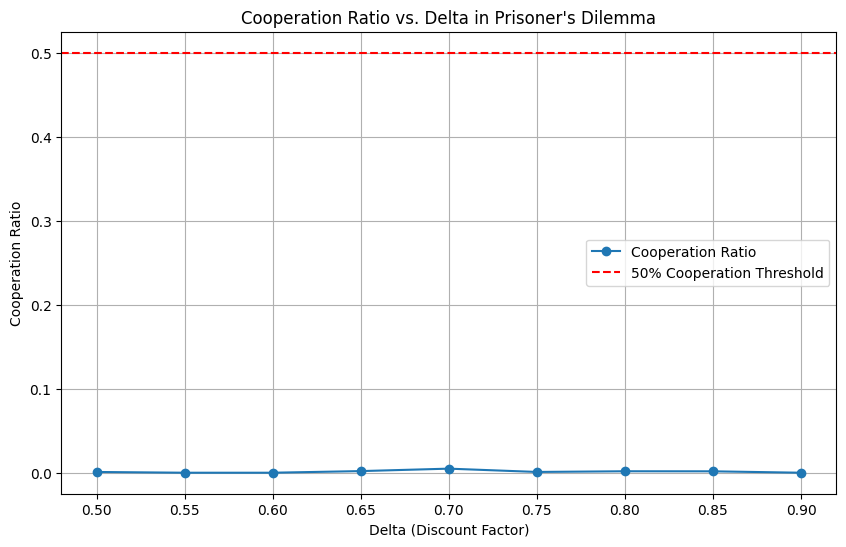

In [ ]:
# Define parameters for the experiment
strategy = GrimTrigger_QValues()
e_initial = epsilon_value
lambda_val = 0.1
alpha = 0.1
delta_range =  (0.5, 0.95, 0.05)# Analyze delta from 0.5 to 1.0 in steps of 0.01
K = 500 # Number of iterations per episode
M = 10  # Number of episodes
e_decay = 1  # Decay rate for exploration
random_uniform = False  # Initialize Q-values randomly

# Run the analysis
deltas, cooperation_ratios = analyze_critical_delta(
    strategy=strategy,
    e_initial=e_initial,
    lambda_val=lambda_val,
    alpha=alpha,
    delta_range=delta_range,
    K=K,
    M=M,
    e_decay=e_decay,
    random_uniform=random_uniform
)


In [ ]:
cooperation_ratios

[0.0008960573476702509,
 0.0,
 0.0,
 0.0019342359767891683,
 0.004849660523763337,
 0.0009191176470588235,
 0.0017452006980802793,
 0.0016736401673640166,
 0.0]